<a href="https://colab.research.google.com/github/darshanukande07/-EE-machine-learning-/blob/main/Project_sem5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from matplotlib.patches import FancyBboxPatch
from scipy.stats import chi2_contingency, mannwhitneyu

from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170})
RS = 42
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
RES = {"versions": {"python": __import__("sys").version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
                    "scikit-learn": sklearn.__version__, "matplotlib": plt.matplotlib.__version__,
                    "seaborn": sns.__version__}}
BLUE, ORANGE, GREEN, RED, GREY = "#2E5C8A", "#E08A2C", "#3C8D5A", "#C0392B", "#8C8C8C"


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


print("Step 1: Environment setup complete. Libraries imported successfully.")

Step 1: Environment setup complete. Libraries imported successfully.


In [ ]:
# STEP 2: DATA LOADING & INITIAL STRUCTURAL INSPECTION
df = pd.read_csv("Travel And Tourism.csv")
print("Step 2: Dataset loaded successfully.")
print(df.shape)
print(df.columns.tolist())
df.head()

Step 2: Dataset loaded successfully.
(1000, 29)
['Booking_ID', 'Booking_Date', 'Travel_Date', 'Return_Date', 'Customer_ID', 'Customer_Name', 'Customer_Age', 'Gender', 'Customer_City', 'Customer_Country', 'Destination_City', 'Destination_Country', 'Number_of_Travellers', 'Number_of_Adults', 'Number_of_Children', 'Hotel_Name', 'Hotel_Rating', 'Number_of_Rooms', 'Number_of_Nights', 'Meal_Plan', 'Payment_Method', 'Booking_Status', 'Cancellation_Status', 'Cancellation_Reason', 'Discount_Amount', 'Customer_Rating', 'Customer_Review_Comment', 'Total_Trip_Cost', 'Transportation_Type']


,Booking_ID,Booking_Date,Travel_Date,Return_Date,Customer_ID,Customer_Name,Customer_Age,Gender,Customer_City,Customer_Country,...,Meal_Plan,Payment_Method,Booking_Status,Cancellation_Status,Cancellation_Reason,Discount_Amount,Customer_Rating,Customer_Review_Comment,Total_Trip_Cost,Transportation_Type
0,1,2026-02-23,2026-04-18,2026-04-21,cust01,Kenzo Vaughn,18,Male,Dubai,United Arab Emirates,...,Breakfast Included,Net Banking,Completed,Not Cancelled,Not Applicable,12800,1.0,Poor service experience,115000,Flight
1,2,2025-05-30,2025-06-29,2025-07-02,cust02,Priya Carter,20,Female,Udaipur,India,...,Full Board,Net Banking,Completed,Not Cancelled,Not Applicable,0,1.5,Poor service experience,56800,Train
2,3,2024-12-30,2025-03-14,2025-03-23,cust03,Elina Vaughn,31,Female,Dubai,United Arab Emirates,...,Full Board,UPI,Completed,Not Cancelled,Not Applicable,74400,2.0,Several arrangements need improvement,669800,Flight
3,4,2026-06-17,2026-09-19,2026-09-26,cust04,Mei Ferraro,30,Male,Kathmandu,Nepal,...,Room Only,Credit Card,Confirmed,Not Cancelled,Not Applicable,4500,0.0,Not yet travelled,84700,Flight
4,5,2025-03-21,2025-04-21,2025-04-24,cust05,Alina Desai,39,Female,Kuala Lumpur,Malaysia,...,Room Only,Digital Wallet,Completed,Not Cancelled,Not Applicable,2800,3.6,Good overall experience,15600,Flight


In [ ]:
RES["quality"] = {
    "rows": int(len(df)), "columns": int(df.shape[1]), "missing_values": int(df.isna().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "status_counts": df.Booking_Status.value_counts().to_dict(),
    "rating_zero_rows": int((df.Customer_Rating == 0).sum()),
    "rating_zero_only_not_completed": bool((df.loc[df.Customer_Rating == 0, "Booking_Status"] != "Completed").all()),
    "completed_rated": int(((df.Booking_Status == "Completed") & (df.Customer_Rating > 0)).sum()),
    "adults_children_match": bool((df.Number_of_Adults + df.Number_of_Children == df.Number_of_Travellers).all()),
    "nights_match_dates": bool(((pd.to_datetime(df.Return_Date) - pd.to_datetime(df.Travel_Date)).dt.days == df.Number_of_Nights).all()),
}
print(json.dumps(RES["quality"], indent=1))

{
 "rows": 1000,
 "columns": 29,
 "missing_values": 0,
 "duplicate_rows": 0,
 "status_counts": {
  "Completed": 772,
  "Cancelled": 141,
  "Confirmed": 79,
  "Pending": 8
 },
 "rating_zero_rows": 228,
 "rating_zero_only_not_completed": true,
 "completed_rated": 772,
 "adults_children_match": true,
 "nights_match_dates": true
}


In [ ]:
df_completed = df[df["Booking_Status"] == "Completed"].copy()
df_completed["Satisfaction_Class"] = (df_completed["Customer_Rating"] >= 3.0).astype(int)
for c in ["Booking_Date", "Travel_Date", "Return_Date"]:
    df_completed[c] = pd.to_datetime(df_completed[c])
df_completed["Lead_Time"] = (df_completed["Travel_Date"] - df_completed["Booking_Date"]).dt.days
df_completed["Trip_Duration"] = (df_completed["Return_Date"] - df_completed["Travel_Date"]).dt.days
df_completed["Per_Capita_Cost"] = df_completed["Total_Trip_Cost"] / df_completed["Number_of_Travellers"]
df_completed["Discount_Ratio"] = df_completed["Discount_Amount"] / df_completed["Total_Trip_Cost"]
RES["target"] = {"n": int(len(df_completed)),
                 "satisfied": int(df_completed.Satisfaction_Class.sum()),
                 "unsatisfied": int((1 - df_completed.Satisfaction_Class).sum()),
                 "mean_rating": float(df_completed.Customer_Rating.mean()),
                 "median_rating": float(df_completed.Customer_Rating.median())}
print(RES["target"])

{'n': 772, 'satisfied': 384, 'unsatisfied': 388, 'mean_rating': 2.9987046632124352, 'median_rating': 2.9}


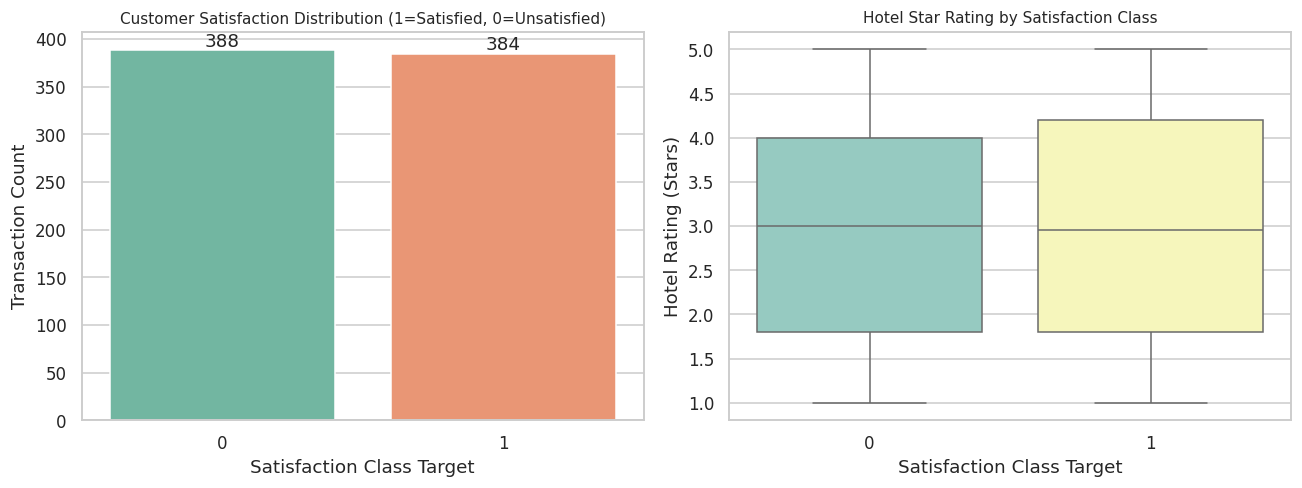

In [ ]:
# Figure 1 (original Colab plots): class balance + hotel rating by class
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
sns.countplot(data=df_completed, x="Satisfaction_Class", palette="Set2", ax=ax[0])
ax[0].set_title("Customer Satisfaction Distribution (1=Satisfied, 0=Unsatisfied)", fontsize=10)
ax[0].set_xlabel("Satisfaction Class Target")
ax[0].set_ylabel("Transaction Count")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
sns.boxplot(data=df_completed, x="Satisfaction_Class", y="Hotel_Rating", palette="Set3", ax=ax[1])
ax[1].set_title("Hotel Star Rating by Satisfaction Class", fontsize=10)
ax[1].set_xlabel("Satisfaction Class Target")
ax[1].set_ylabel("Hotel Rating (Stars)")
save(fig, "fig_01_class_balance_hotel_rating")

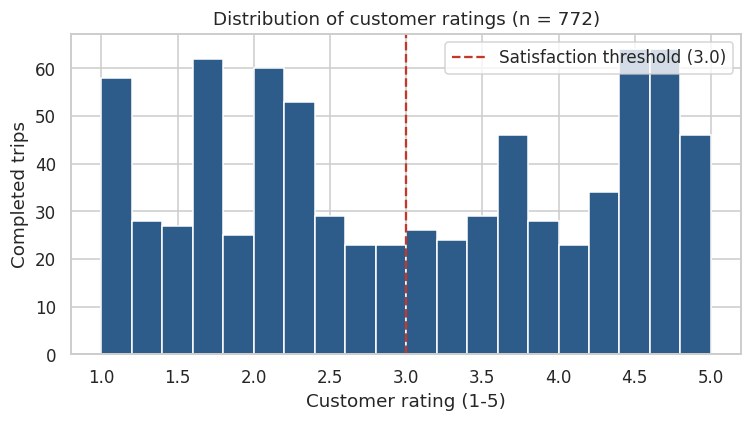

In [ ]:
# Figure 2: rating distribution
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df_completed.Customer_Rating, bins=20, color=BLUE, edgecolor="white")
ax.axvline(3.0, color=RED, ls="--", label="Satisfaction threshold (3.0)")
ax.set_xlabel("Customer rating (1-5)")
ax.set_ylabel("Completed trips")
ax.set_title(f"Distribution of customer ratings (n = {len(df_completed)})")
ax.legend()
save(fig, "fig_02_rating_distribution")

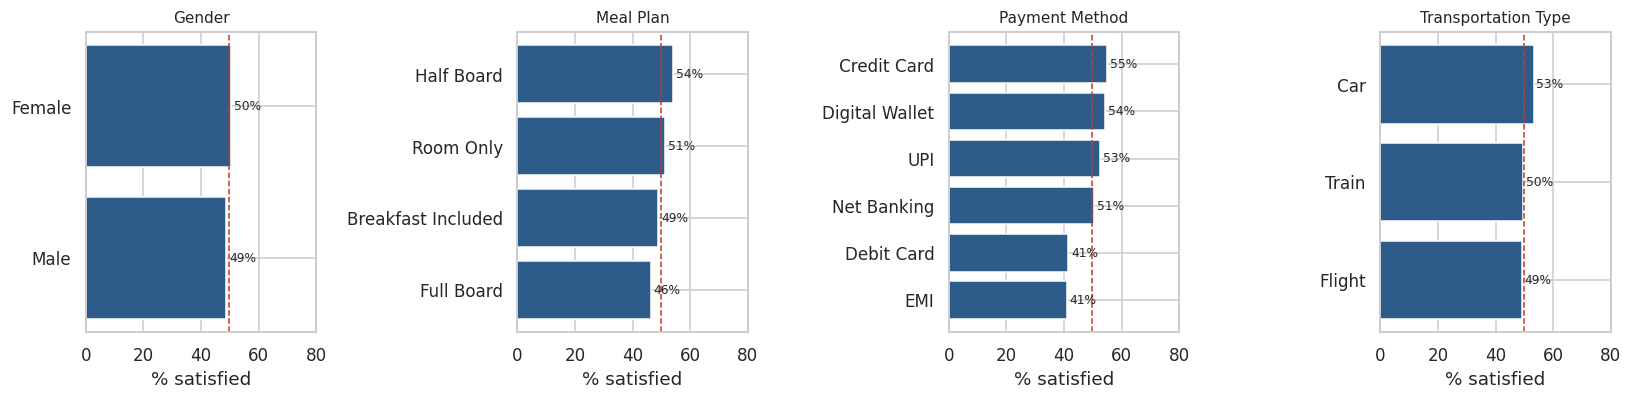

In [ ]:
# Figure 3: satisfaction rate by categorical variables + chi-square tests
cat_cols = ["Gender", "Meal_Plan", "Payment_Method", "Transportation_Type"]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True)
chi = {}
for a, c in zip(ax, cat_cols):
    r = (df_completed.groupby(c).Satisfaction_Class.mean() * 100).sort_values()
    a.barh(r.index, r.values, color=BLUE)
    a.axvline(df_completed.Satisfaction_Class.mean() * 100, color=RED, ls="--", lw=1)
    a.set_title(c.replace("_", " "), fontsize=10)
    a.set_xlabel("% satisfied")
    a.set_xlim(0, 80)
    for i, v in enumerate(r.values):
        a.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8)
    stat, p, dof, _ = chi2_contingency(pd.crosstab(df_completed[c], df_completed.Satisfaction_Class))
    chi[c] = {"chi2": float(stat), "dof": int(dof), "p_value": float(p)}
save(fig, "fig_03_satisfaction_by_category")
RES["chi_square"] = chi

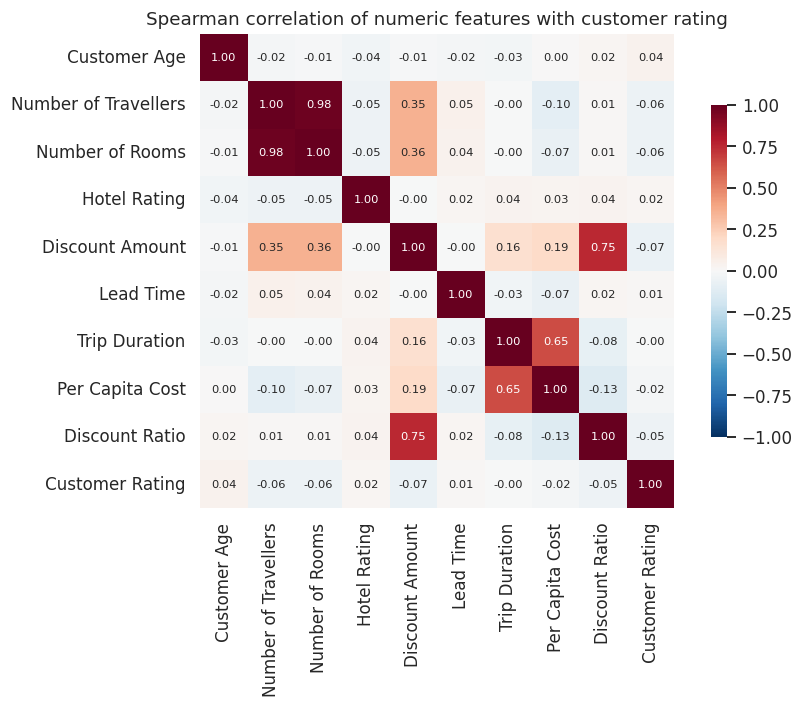

,median_satisfied,median_unsatisfied,p_value
Customer_Age,35.0000,34.0000,0.5240
Number_of_Travellers,5.0000,5.0000,0.3455
Number_of_Rooms,3.0000,3.0000,0.4014
Hotel_Rating,2.9500,3.0000,0.6738
Discount_Amount,7000.0000,8450.0000,0.1213
Lead_Time,91.5000,89.0000,0.9547
Trip_Duration,5.0000,5.0000,0.5682
Per_Capita_Cost,30063.3333,30466.6667,0.2396
Discount_Ratio,0.0528,0.0531,0.2973


In [ ]:
# Statistical tests for numeric features (Mann-Whitney U: satisfied vs unsatisfied)
NUM = ["Customer_Age", "Number_of_Travellers", "Number_of_Rooms", "Hotel_Rating", "Discount_Amount", "Lead_Time",
       "Trip_Duration", "Per_Capita_Cost", "Discount_Ratio"]
mw = {}
for c in NUM:
    a_ = df_completed.loc[df_completed.Satisfaction_Class == 1, c]
    b_ = df_completed.loc[df_completed.Satisfaction_Class == 0, c]
    u, p = mannwhitneyu(a_, b_)
    mw[c] = {"median_satisfied": float(a_.median()), "median_unsatisfied": float(b_.median()), "p_value": float(p)}
RES["mann_whitney"] = mw
corr = df_completed[NUM + ["Customer_Rating"]].corr(method="spearman")
RES["corr_with_rating"] = {k: float(v) for k, v in corr["Customer_Rating"].drop("Customer_Rating").items()}
fig, ax = plt.subplots(figsize=(8.5, 6.6))
labels = [c.replace("_", " ") for c in corr.columns]
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            xticklabels=labels, yticklabels=labels, cbar_kws={"shrink": 0.7}, annot_kws={"size": 7.5}, ax=ax)
ax.set_title("Spearman correlation of numeric features with customer rating")
save(fig, "fig_04_correlation")
pd.DataFrame(mw).T.round(4)

In [ ]:
# STEP 6: FEATURE SELECTION, ENCODING AND MISSING VALUES
feature_cols = ["Customer_Age", "Number_of_Travellers", "Number_of_Rooms", "Hotel_Rating", "Discount_Amount",
                "Lead_Time", "Trip_Duration", "Per_Capita_Cost", "Discount_Ratio", "Gender", "Meal_Plan",
                "Payment_Method", "Transportation_Type"]
X = df_completed[feature_cols].copy()
y = df_completed["Satisfaction_Class"].values
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    label_encoders[col] = le
X.fillna(X.median(), inplace=True)
RES["features"] = {"all": feature_cols, "categorical": cat_cols, "engineered": ["Lead_Time", "Trip_Duration", "Per_Capita_Cost", "Discount_Ratio"],
                   "missing_after_fill": int(X.isna().sum().sum())}

In [ ]:
# STEP 7: STRATIFIED SPLIT (70% train, 15% validation, 15% test)
# Feature scaling is not needed: a Random Forest splits on thresholds and is unaffected by feature scale.
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1765, random_state=42, stratify=y_train_val)
RES["split"] = {"train": int(X_train.shape[0]), "validation": int(X_val.shape[0]), "test": int(X_test.shape[0]),
                "train_pos": int(y_train.sum()), "val_pos": int(y_val.sum()), "test_pos": int(y_test.sum())}
print(f"Data Partition Sizes: Train={X_train.shape[0]}, Validation={X_val.shape[0]}, Test={X_test.shape[0]}")

Data Partition Sizes: Train=540, Validation=116, Test=116


In [ ]:
# STEP 8: MODEL TRAINING AND EVALUATION (Random Forest - proposed model)
# NOTE (bug fixed): in the original Colab the metric calculation and results_list.append(...) were indented
# outside the `for` loop. They are inside the loop here, and the validation set and cross-validation are added.
models = {
    "Random Forest (Proposed)": RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_split=4, random_state=42),
}
RES["hyperparameters"] = {"Random Forest (Proposed)": "n_estimators=100, max_depth=12, min_samples_split=4, random_state=42"}


def metrics(model, Xs, ys):
    pred = model.predict(Xs)
    proba = model.predict_proba(Xs)[:, 1]
    return {"accuracy": accuracy_score(ys, pred) * 100, "precision": precision_score(ys, pred, zero_division=0),
            "recall": recall_score(ys, pred), "f1": f1_score(ys, pred), "roc_auc": roc_auc_score(ys, proba),
            "cm": confusion_matrix(ys, pred).tolist()}, proba


results_list, test_proba, val_proba = [], {}, {}
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
for name, model in models.items():
    model.fit(X_train, y_train)          # tree ensembles use the original (unscaled) features
    val_m, vp = metrics(model, X_val, y_val)
    test_m, proba = metrics(model, X_test, y_test)
    test_proba[name], val_proba[name] = proba, vp
    cvs = cross_val_score(clone(model), X_train_val, y_train_val, cv=cv, scoring="accuracy")
    results_list.append({"model": name, "validation": val_m, "test": test_m,
                         "cv_acc_mean": float(cvs.mean() * 100), "cv_acc_std": float(cvs.std() * 100)})
    print(f"{name}: val acc {val_m['accuracy']:.2f} | test acc {test_m['accuracy']:.2f} | test AUC {test_m['roc_auc']:.3f} | CV acc {cvs.mean()*100:.2f}")
RES["models"] = results_list
RES["chance"] = {"majority_test_acc": float(max(y_test.mean(), 1 - y_test.mean()) * 100)}

results_df = pd.DataFrame([{"Model Architecture": r["model"], "Accuracy (%)": round(r["test"]["accuracy"], 2),
                            "Precision": round(r["test"]["precision"], 2), "Recall": round(r["test"]["recall"], 2),
                            "F1-Score": round(r["test"]["f1"], 2), "ROC-AUC": round(r["test"]["roc_auc"], 2)} for r in results_list])
print("=" * 70)
print("FINAL MODEL PERFORMANCE MATRIX (TEST SET)")
print("=" * 70)
print(results_df.to_string(index=False))

Random Forest (Proposed): val acc 50.86 | test acc 54.31 | test AUC 0.564 | CV acc 49.24
FINAL MODEL PERFORMANCE MATRIX (TEST SET)
      Model Architecture  Accuracy (%)  Precision  Recall  F1-Score  ROC-AUC
Random Forest (Proposed)         54.31       0.54    0.59      0.56     0.56


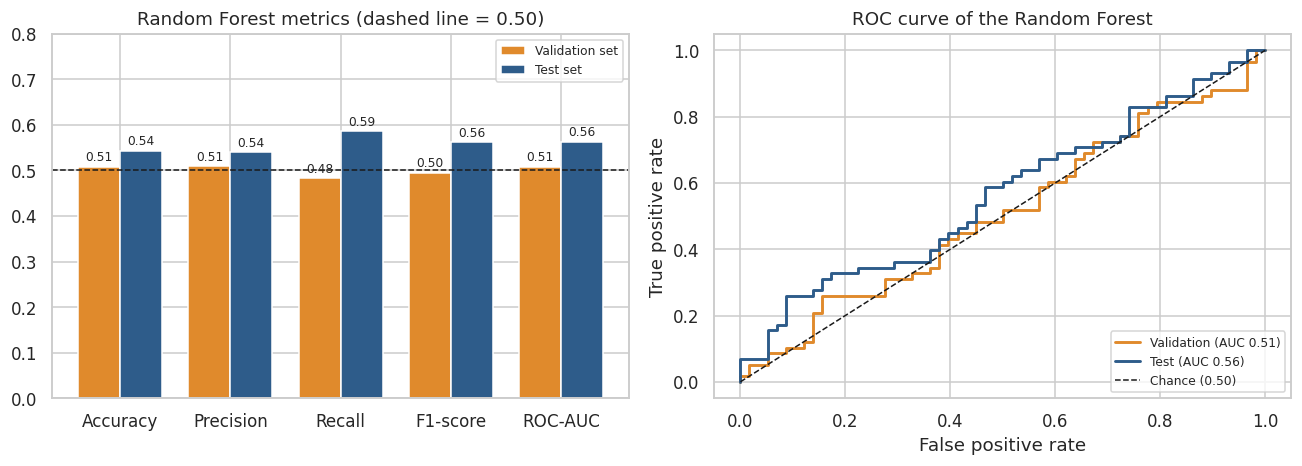

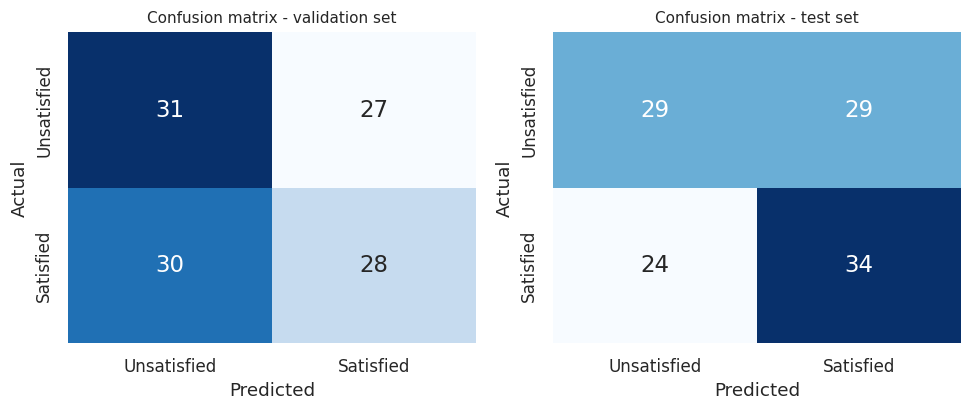

In [ ]:
# STEP 9: PERFORMANCE PLOTS - METRICS, ROC CURVE AND CONFUSION MATRICES
r0 = results_list[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
labs = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
keys = ["accuracy", "precision", "recall", "f1", "roc_auc"]
xx = np.arange(5)
for k_, (part, col, lab) in enumerate([("validation", ORANGE, "Validation set"), ("test", BLUE, "Test set")]):
    vals = [r0[part][k] / (100 if k == "accuracy" else 1) for k in keys]
    bars = ax[0].bar(xx + (k_ - 0.5) * 0.38, vals, 0.38, color=col, label=lab)
    ax[0].bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax[0].axhline(0.5, color="k", ls="--", lw=1)
ax[0].set_xticks(xx, labs)
ax[0].set_ylim(0, 0.8)
ax[0].set_title("Random Forest metrics (dashed line = 0.50)")
ax[0].legend(loc="upper right", fontsize=8)
for (part, col, ys_, pr_) in [("Validation", ORANGE, y_val, val_proba["Random Forest (Proposed)"]), ("Test", BLUE, y_test, test_proba["Random Forest (Proposed)"])]:
    fpr, tpr, _ = roc_curve(ys_, pr_)
    ax[1].plot(fpr, tpr, color=col, lw=1.9, label=f"{part} (AUC {roc_auc_score(ys_, pr_):.2f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="Chance (0.50)")
ax[1].set_xlabel("False positive rate")
ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curve of the Random Forest")
ax[1].legend(fontsize=8, loc="lower right")
save(fig, "fig_05_metrics_roc")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.9))
for a, part in zip(ax, ["validation", "test"]):
    sns.heatmap(np.array(r0[part]["cm"]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Unsatisfied", "Satisfied"], yticklabels=["Unsatisfied", "Satisfied"], annot_kws={"size": 15})
    a.set_title(f"Confusion matrix - {part} set", fontsize=10)
    a.set_xlabel("Predicted")
    a.set_ylabel("Actual")
save(fig, "fig_06_confusion_matrices")

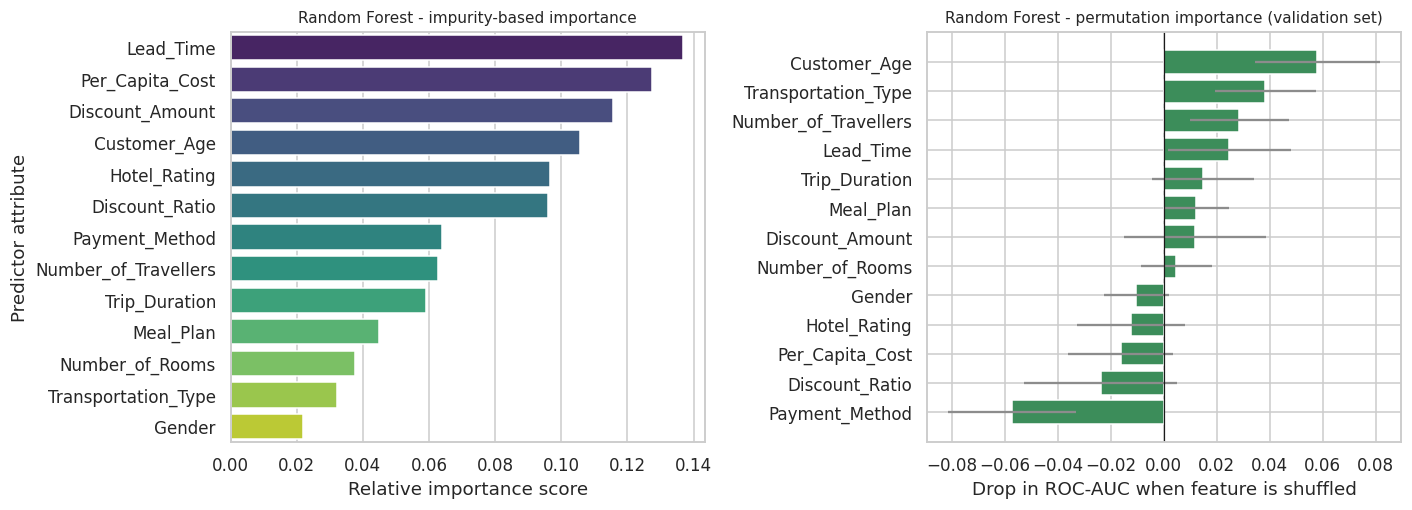

Processing complete. All empirical metrics successfully evaluated.


In [ ]:
# STEP 10: PROPOSED MODEL FEATURE IMPORTANCE VISUALIZATION
rf_best = models["Random Forest (Proposed)"]
feature_imp_df = pd.DataFrame({"Feature": X.columns, "Importance": rf_best.feature_importances_}).sort_values("Importance", ascending=False)
perm = permutation_importance(rf_best, X_val, y_val, scoring="roc_auc", n_repeats=30, random_state=RS)
perm_df = pd.DataFrame({"Feature": X.columns, "mean": perm.importances_mean, "std": perm.importances_std}).sort_values("mean", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(data=feature_imp_df, x="Importance", y="Feature", palette="viridis", ax=ax[0])
ax[0].set_title("Random Forest - impurity-based importance", fontsize=10)
ax[0].set_xlabel("Relative importance score")
ax[0].set_ylabel("Predictor attribute")
ax[1].barh(perm_df.Feature[::-1], perm_df["mean"][::-1], xerr=perm_df["std"][::-1], color=GREEN, ecolor=GREY)
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_title("Random Forest - permutation importance (validation set)", fontsize=10)
ax[1].set_xlabel("Drop in ROC-AUC when feature is shuffled")
save(fig, "fig_08_feature_importance")
RES["importance"] = {"impurity": feature_imp_df.round(4).to_dict("records"), "permutation": perm_df.round(4).to_dict("records")}
print("Processing complete. All empirical metrics successfully evaluated.")

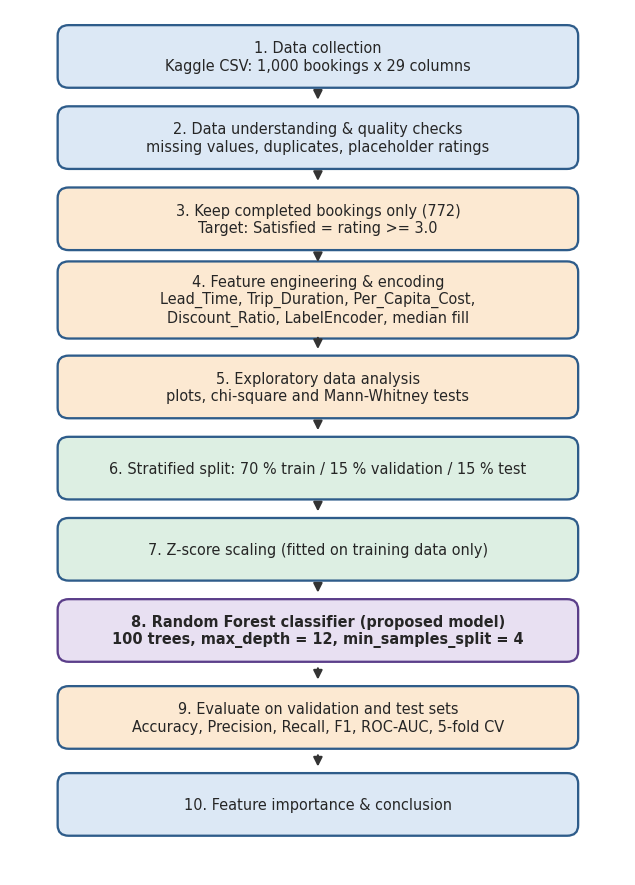

In [ ]:
# FLOWCHART (used in the report, Section 4.3)
def box(ax, x, y, w, h, text, fc="#DCE8F5", ec="#2E5C8A", fs=9.5, bold=False):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.04,rounding_size=0.18", fc=fc, ec=ec, lw=1.5))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal")


def arrow(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4))


fig, ax = plt.subplots(figsize=(7.2, 10.2))
ax.set_xlim(0, 10)
ax.set_ylim(-0.3, 14.6)
ax.axis("off")
steps = [(13.8, "1. Data collection\nKaggle CSV: 1,000 bookings x 29 columns", "#DCE8F5"),
         (12.4, "2. Data understanding & quality checks\nmissing values, duplicates, placeholder ratings", "#DCE8F5"),
         (11.0, "3. Keep completed bookings only (772)\nTarget: Satisfied = rating >= 3.0", "#FCE9D2"),
         (9.6, "4. Feature engineering & encoding\nLead_Time, Trip_Duration, Per_Capita_Cost,\nDiscount_Ratio, LabelEncoder, median fill", "#FCE9D2"),
         (8.1, "5. Exploratory data analysis\nplots, chi-square and Mann-Whitney tests", "#FCE9D2"),
         (6.7, "6. Stratified split: 70 % train / 15 % validation / 15 % test", "#DDEFE3"),
         (5.3, "7. Z-score scaling (fitted on training data only)", "#DDEFE3"),
         (3.9, "8. Random Forest classifier (proposed model)\n100 trees, max_depth = 12, min_samples_split = 4", "#E8E0F2"),
         (2.4, "9. Evaluate on validation and test sets\nAccuracy, Precision, Recall, F1, ROC-AUC, 5-fold CV", "#FCE9D2"),
         (0.9, "10. Feature importance & conclusion", "#DCE8F5")]
for y_, t, c in steps:
    box(ax, 5, y_, 8.4, 1.0 if t.count("\n") < 2 else 1.25, t, fc=c, ec="#5B3E8A" if c == "#E8E0F2" else "#2E5C8A", bold=c == "#E8E0F2")
for i in range(len(steps) - 1):
    arrow(ax, 5, steps[i][0] - 0.6, 5, steps[i + 1][0] + 0.6)
fig.savefig(FIG / "fig_00_flowchart.png", dpi=170, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

In [ ]:
# SAVE RESULTS
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o


(ROOT / "outputs").mkdir(exist_ok=True)
results_df.to_csv(ROOT / "outputs" / "results_rf_metrics.csv", index=False)
(ROOT / "outputs" / "results.json").write_text(json.dumps(clean(RES), indent=2))
print("Saved results.json and", len(list(FIG.glob("*.png"))), "figures")

Saved results.json and 8 figures


In [ ]:
import shutil
from google.colab import files

# FINAL STEP - download all figures and result tables for the report
shutil.make_archive("/content/project_outputs", "zip", ROOT / "outputs")
files.download("/content/project_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>